# 07. Reporte de corte: evaluación final de ResNet50 en palta Hass

Fecha de corte: 26 de octubre de 2026  
Proyecto: diferenciación de defectos superficiales de palta Hass mediante visión artificial y aprendizaje profundo  
Clases: PICADURA y RUSSET  
Modelo seleccionado: `FT_D1_PHOTO_s42_01`  
Estado: entrenamiento cerrado; evaluación única de TEST completada.

Este notebook documenta el desarrollo experimental desde B0 hasta la evaluación final de TEST. Es un informe de lectura: las tablas, figuras y conclusiones están incorporadas y se pueden revisar sin ejecutar código. Las dos celdas opcionales del final solo leen resultados guardados; no entrenan modelos, no cambian el dataset y no repiten TEST.

Alcance de la evidencia: valores de las salidas de Jupyter compartidas durante la ejecución, reportes anteriores y notebook de evaluación. En este entorno no se han abierto los archivos JSON/CSV almacenados en el equipo local; su comprobación opcional se incluye al final.


## 1. Resumen del corte

El clasificador final fue una ResNet50 preentrenada en ImageNet, ajustada sobre los defectos PICADURA y RUSSET. La selección del modelo se efectuó utilizando Macro-F1 en validation antes de abrir TEST. El conjunto reservado se evaluó una sola vez, con el checkpoint congelado y sin ajustar el umbral de decisión.

| Indicador final | Valor observado |
|:--|--:|
| TIFF elegibles en TEST | 126 |
| Clasificaciones correctas | 119 |
| Errores | 7 |
| Accuracy de TEST | 0.9444 (94.44 %) |
| Macro-F1 de TEST | 0.9019 |
| Balanced accuracy de TEST | 0.9264 |
| Recall de RUSSET en TEST | 0.9000 (18 de 20) |
| F1 de RUSSET en TEST | 0.8372 |
| Checkpoint seleccionado | `mejor_finetune.weights.h5` |

El resultado es favorable dentro del conjunto reservado utilizado. Aun así, la cantidad de RUSSET de TEST es reducida y no se ha verificado el comportamiento en otras cámaras, lotes o campañas independientes.


## 2. Unidad de análisis y estructura de las imágenes

Cada archivo TIFF corresponde a una palta y posee una etiqueta única. La imagen está organizada en tres franjas horizontales, una por cámara. En cada franja se observan distintas vistas de la misma palta durante su rotación.

La unidad para entrenamiento, validation y TEST es el TIFF completo, no cada franja ni cada vista por separado. Por eso se conserva la información multivista y se evita distribuir imágenes derivadas de un mismo TIFF en particiones distintas. No se aplicaron volteos horizontales porque alteran el orden de captura de las vistas.

La tarea abordada es clasificación binaria por palta. El trabajo no presenta una localización pixel a pixel del defecto, ni estima su extensión real sobre la superficie.


## 3. Auditoría del dataset y particiones

Se inventariaron 829 imágenes originales. La auditoría propuso cuatro exclusiones lógicas asociadas con duplicidad y consistencia entre particiones. Las exclusiones se realizaron en los listados usados para el entrenamiento y la evaluación, sin borrar archivos TIFF.

| Partición | PICADURA elegible | RUSSET elegible | Total elegible |
|:--|--:|--:|--:|
| Train | 495 | 77 | 572 |
| Validation | 106 | 21 | 127 |
| TEST | 106 | 20 | 126 |
| Total | 707 | 118 | 825 |

Antes de la inferencia final, el procedimiento notificó la verificación de integridad de 829/829 archivos mediante SHA-256. También se comprobó la compatibilidad de las firmas del inventario y del protocolo. El número total elegible fue 825 y TEST conservó 126 imágenes.

La auditoría de duplicados exactos no demuestra por sí sola independencia estadística por lote, fecha, sesión de captura o proveedor. Esa trazabilidad adicional sigue siendo una limitación del estudio.


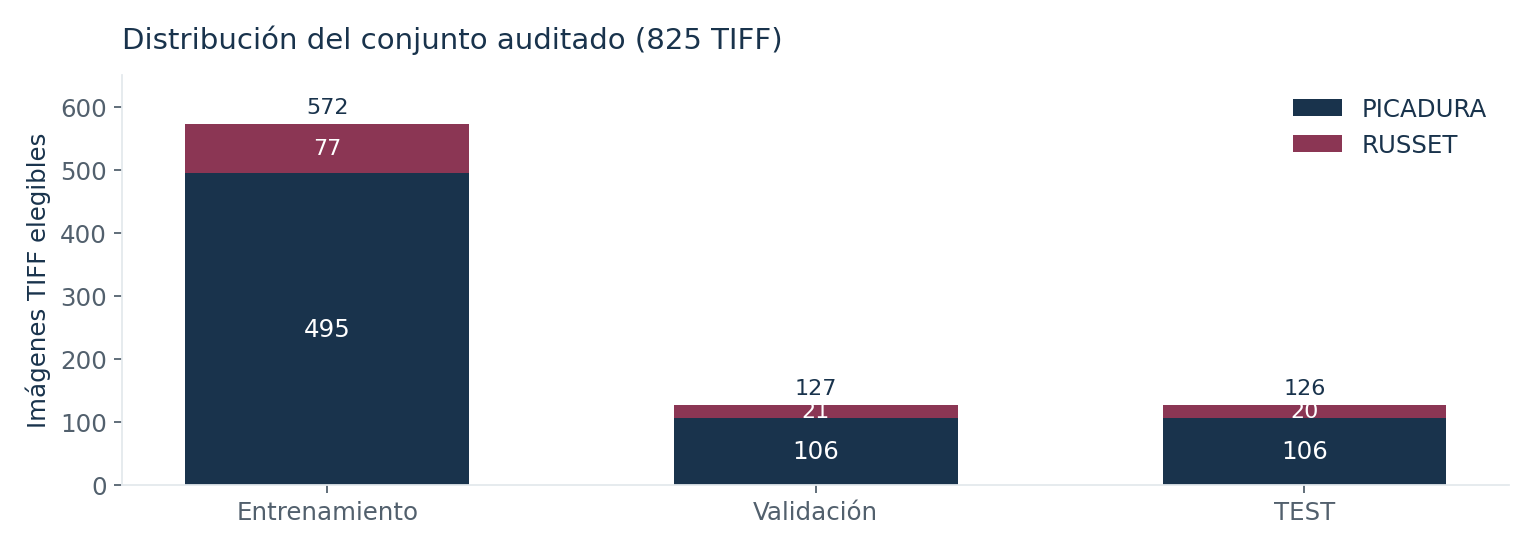

Figura 1. Distribución de los 825 TIFF elegibles por partición y clase.


## 4. Arquitectura y protocolo de entrenamiento

| Elemento | Configuración empleada |
|:--|:--|
| Red | ResNet50, inicializada con pesos ImageNet |
| Entrada | TIFF completo convertido a RGB, valores 0–255 |
| Tamaño de entrada | 256 × 512 píxeles |
| Ajuste de dimensiones | Redimensionamiento conservando proporción, con relleno |
| Preprocesamiento de red | `preprocess_input` de ResNet50, incluido dentro del modelo |
| Cabeza de clasificación | Global average pooling de ResNet50, Dropout 0.35, Dense softmax de dos clases |
| Fine-tuning | Bloque `conv5`, conservando BatchNormalization congelada |
| Épocas máximas | 8 |
| Tamaño de lote | 1 imagen |
| Tasa de aprendizaje del fine-tuning | `1e-5` |
| Selección de checkpoint | Mínimo `val_loss` en validation |
| Semilla de ejecución | 42 |
| Inferencia final | Sin aumentos; etiqueta por `argmax` del softmax |

El experimento D1 añadió 77 copias fotométricas suaves de RUSSET durante train, lo que elevó el plan a 649 muestras por época. En FT_D1_PHOTO se mantuvo ese plan D1 y se añadieron variaciones aleatorias de brillo y contraste dentro de 0.95–1.05 durante el entrenamiento en ambas clases. Los TIFF originales no se modificaron.

Los parámetros anteriores describen las corridas documentadas; no son una demostración de que exista una configuración globalmente óptima.


## 5. Secuencia experimental completa en validation

Todos los resultados de esta tabla corresponden a las mismas 127 imágenes elegibles de validation. Se muestran los valores guardados de cada corrida, no métricas de TEST.

| Condición | Cambio principal | Accuracy | Macro-F1 | Recall RUSSET | RUSSET correctas |
|:--|:--|--:|--:|--:|--:|
| B0 | ResNet50 congelada, 256 × 512 | 0.8425 | 0.6604 | 0.3333 | 7/21 |
| V1 | Mayor resolución, 384 × 768 | 0.8583 | 0.6598 | 0.2857 | 6/21 |
| D1 | Una copia suave por RUSSET de train | 0.8425 | 0.7033 | 0.4762 | 10/21 |
| D2 | Dos copias suaves por RUSSET de train | 0.8583 | 0.6944 | 0.3810 | 8/21 |
| FT_B0 | Fine-tuning del bloque conv5 desde B0 | 0.8661 | 0.7183 | 0.4286 | 9/21 |
| FT_D1 | Fine-tuning de conv5 desde D1 | 0.8740 | 0.7524 | 0.5238 | 11/21 |
| FT_D1_PHOTO | FT_D1 con variaciones adicionales suaves en train | 0.8740 | 0.7876 | 0.7143 | 15/21 |

La mayor resolución de V1 no produjo una mejora de Macro-F1 frente a B0. D1 sí mejoró la detección de la clase minoritaria; duplicar nuevamente las copias en D2 no ofreció una mejora adicional. El ajuste fino de conv5 elevó el Macro-F1 y el experimento FT_D1_PHOTO alcanzó el valor más alto registrado en validation.

Como se compararon varias alternativas utilizando una misma partición, existe riesgo de adaptación indirecta a validation. La elección final se cerró antes de utilizar TEST.


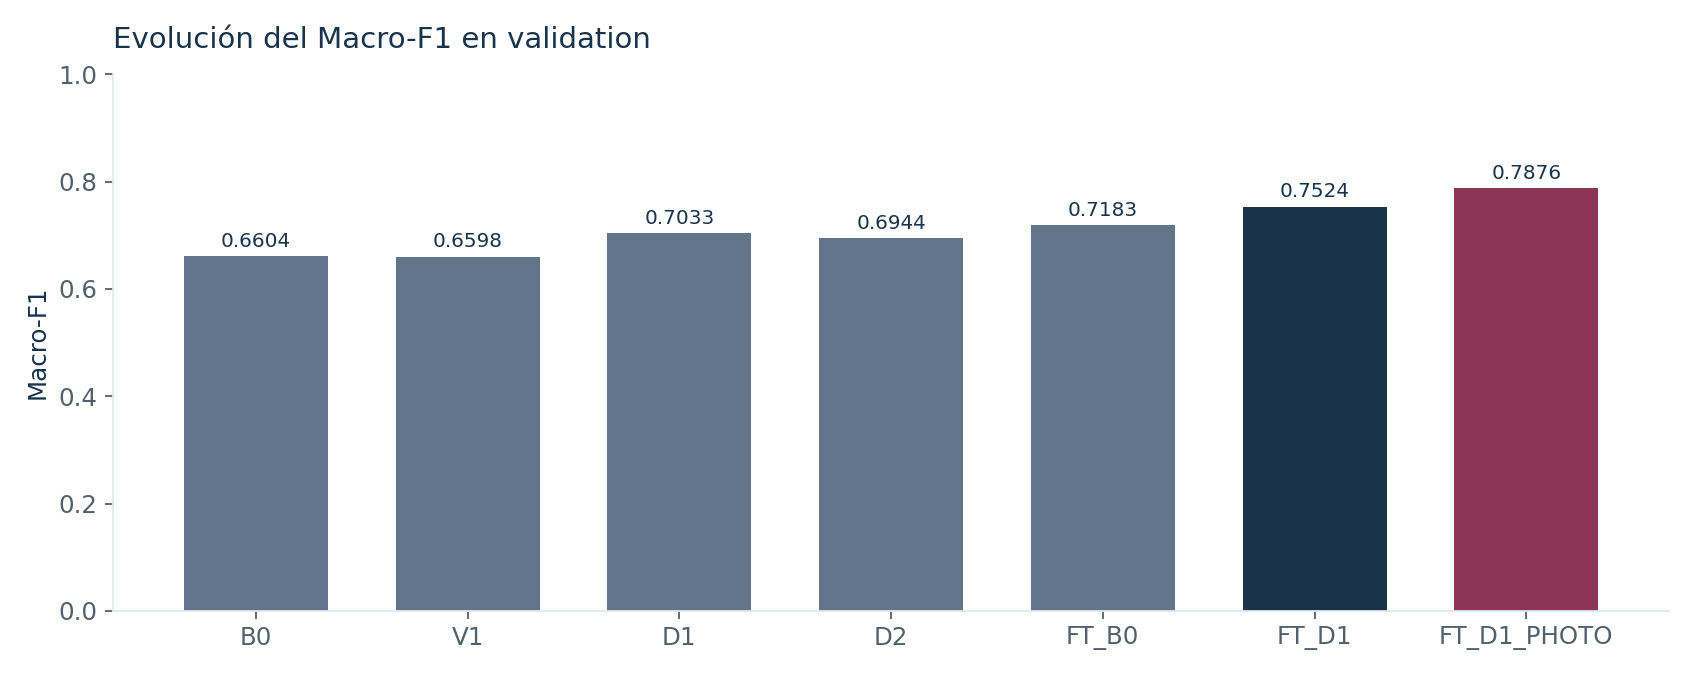

Figura 2. Evolución de Macro-F1 para las siete configuraciones evaluadas.


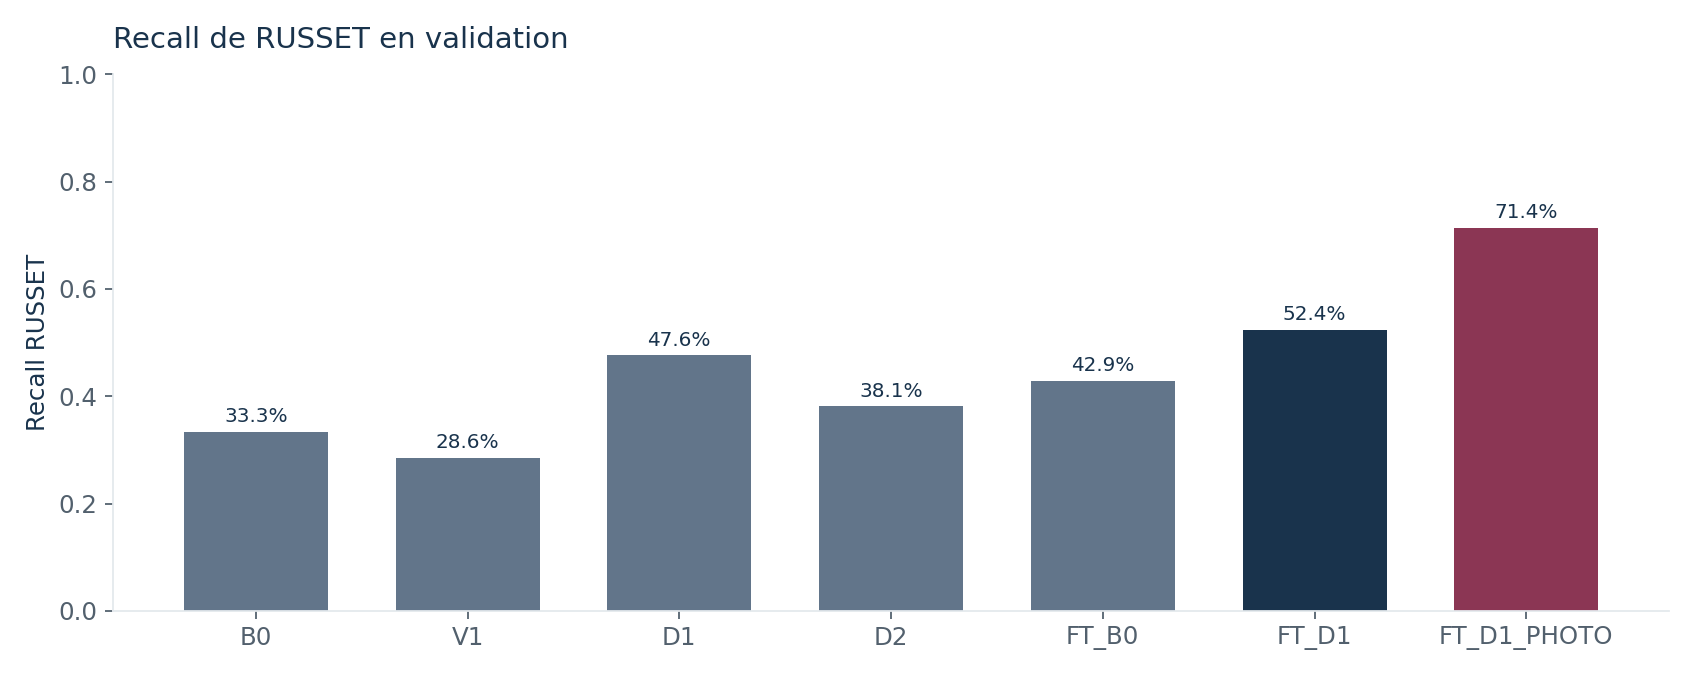

Figura 3. Recall de la clase RUSSET en validation.


## 6. Ensayo exploratorio de iluminación en inferencia

Antes de FT_D1_PHOTO se probó aumentar directamente el brillo ×2 y el contraste ×1.25 en las 127 imágenes de validation, utilizando el modelo FT_D1 sin reentrenamiento.

| Métrica | Imagen original | Imagen con brillo y contraste |
|:--|--:|--:|
| Accuracy | 0.8740 | 0.8583 |
| Macro-F1 | 0.7524 | 0.7433 |
| Recall RUSSET | 0.5238 | 0.5714 |
| Errores corregidos | — | 4 |
| Errores nuevos | — | 6 |

Se corrigieron cuatro errores y aparecieron seis nuevos. Este ensayo no mejoró el Macro-F1 global. La modificación fuerte durante inferencia debe diferenciarse del experimento posterior FT_D1_PHOTO, donde se usaron variaciones pequeñas y aleatorias durante el entrenamiento.

Este contraste no demuestra causalidad: las condiciones de captura y la similitud visual de los defectos requieren un estudio adicional.


## 7. Selección de FT_D1_PHOTO por Macro-F1

La comparación en validation entre los dos modelos más avanzados mostró el mismo número total de aciertos, pero una distribución diferente por clase.

| Métrica | FT_D1 | FT_D1_PHOTO | Cambio |
|:--|--:|--:|--:|
| Accuracy | 0.8740 | 0.8740 | 0.0000 |
| Macro-F1 | 0.7524 | 0.7876 | +0.0352 |
| Recall RUSSET | 0.5238 | 0.7143 | +0.1905 |
| Precision RUSSET | 0.6471 | 0.6000 | −0.0471 |
| Aciertos RUSSET | 11/21 | 15/21 | +4 |
| Aciertos totales | 111/127 | 111/127 | Igual |

Análisis emparejado de las predicciones: se conservaron 105 aciertos, se corrigieron seis errores y se introdujeron seis errores. Entre las correcciones hubo dos PICADURA y cuatro RUSSET. Los seis nuevos errores fueron PICADURA clasificadas como RUSSET.

La elección de FT_D1_PHOTO fue coherente con el criterio principal Macro-F1. Sin embargo, mejor recall de RUSSET no significa menor costo operativo en todos los escenarios: aumentaron los falsos positivos de RUSSET en validation.


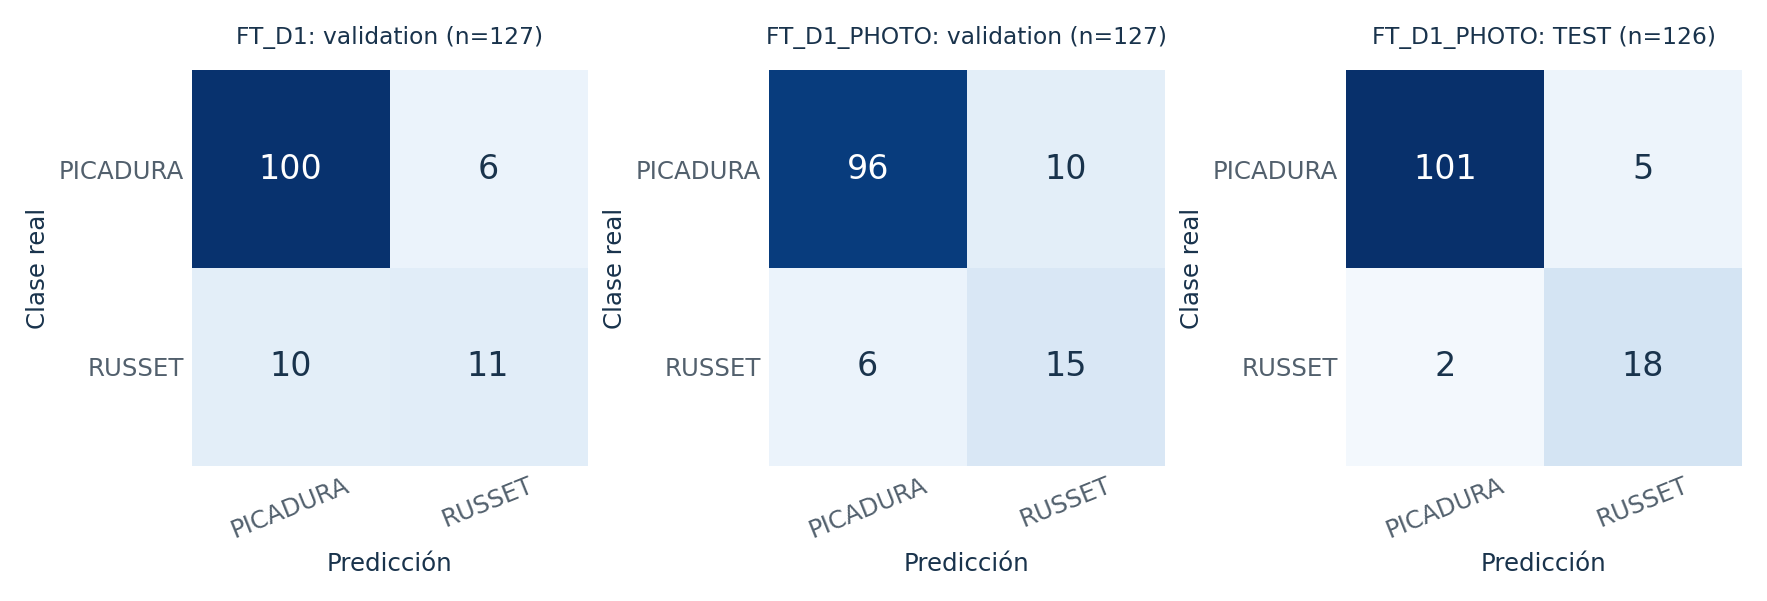

Figura 4. Matrices de confusión de FT_D1 y FT_D1_PHOTO en validation, y FT_D1_PHOTO en TEST. Filas: clase real; columnas: clase predicha.


## 8. Curvas de aprendizaje y checkpoint seleccionado

El entrenamiento FT_D1_PHOTO se completó en ocho épocas. El registro del checkpoint mostró que la mejor época por `val_loss` fue la 5. Durante las últimas épocas, la exactitud de entrenamiento se acercó al 99 %, mientras que la pérdida de validation osciló y volvió a subir después de su mínimo.

La separación entre entrenamiento y validación es compatible con sobreajuste, aunque la curva aislada no permite establecer la causa. Para la evaluación final se recuperaron los pesos del checkpoint seleccionado, no los de la última época.

Las figuras siguientes se conservaron desde el reporte del experimento; representan las curvas originales mostradas por el notebook de entrenamiento.


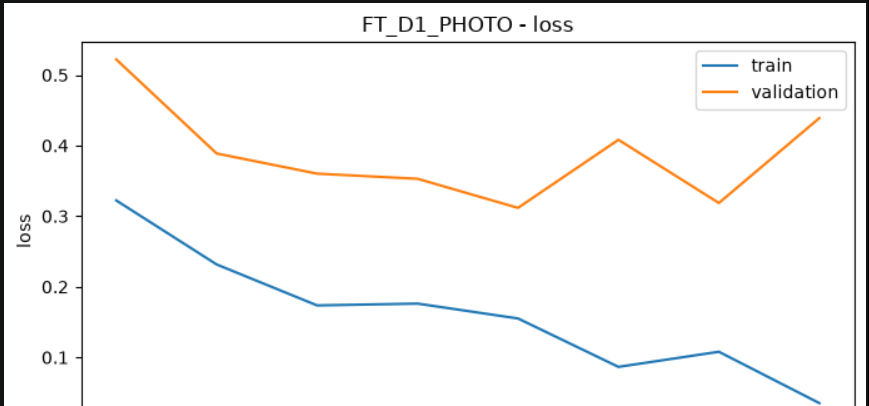

Figura 5. Curvas originales de pérdida de entrenamiento y validación durante FT_D1_PHOTO.


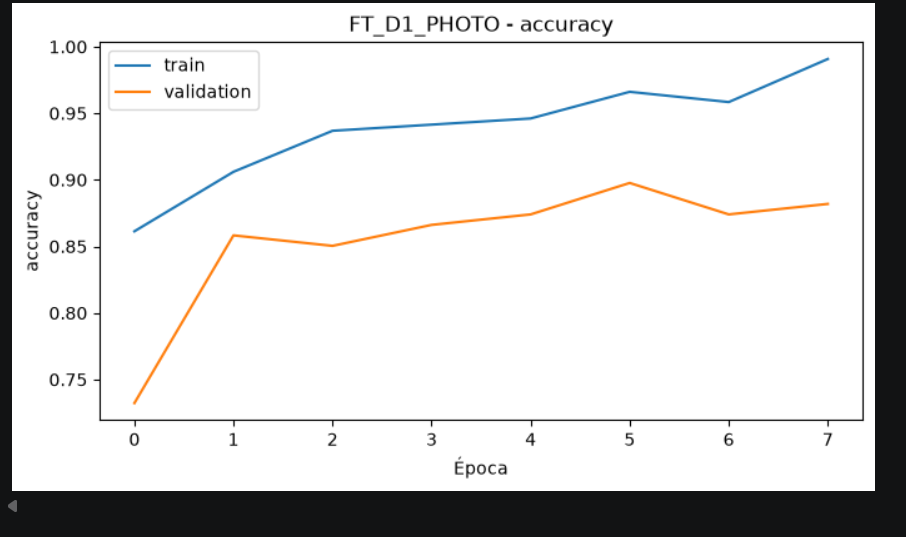

Figura 6. Curvas originales de exactitud de entrenamiento y validación durante FT_D1_PHOTO.


## 9. Identidad del checkpoint y reproducción de validation

Antes de TEST se reconstruyó ResNet50 y se cargaron los pesos guardados. Se comprobó que las capas quedaran sin entrenamiento activo y se registró la huella del checkpoint:

`d273174144bc2b3a9a2835665a38edf028623bd9ef5eabe6c70a068a9032717e`

La comprobación SHA-256 fue consistente al reiniciar el kernel de Jupyter. La GPU detectada fue NVIDIA GeForce RTX 3070 Ti Laptop GPU. No se ejecutó entrenamiento durante la evaluación final.

La reproducción de validation no fue idéntica al archivo histórico. Los resultados completos fueron:

| Verificación | Resultado |
|:--|--:|
| Predicciones históricas | 127 |
| Etiquetas coincidentes | 126 |
| Etiquetas distintas | 1 |
| Mayor diferencia absoluta entre probabilidades | 0.004967 |
| Accuracy histórico | 0.8740 |
| Macro-F1 histórico | 0.7876 |
| Accuracy reproducido | 0.8661 |
| Macro-F1 reproducido | 0.7781 |

Una imagen PICADURA cambió de PICADURA a RUSSET cuando su puntuación RUSSET pasó de 0.499474 a 0.502148. Ambos valores están muy cerca del límite 0.5. La causa precisa de la diferencia no quedó determinada. El hecho de repetir la discrepancia con más memoria GPU disponible no permite atribuirla exclusivamente a limitaciones de memoria.

Para continuar se aceptó una compatibilidad numérica restringida: diferencia máxima de probabilidad no superior a 0.02, como máximo una etiqueta discordante y siempre junto al umbral. Este criterio de tolerancia fue establecido después de observar la discrepancia, por lo que se informa como una concesión metodológica, no como una reproducción exacta. Se conservó el checkpoint original y no se modificaron umbrales, pesos ni etiquetas.


## 10. Protocolo de la evaluación final de TEST

Después de seleccionar FT_D1_PHOTO utilizando validation se fijaron las condiciones para la evaluación reservada:

- Conjunto de prueba: 126 TIFF elegibles, de los cuales 106 son PICADURA y 20 RUSSET.
- Auditoría local completa: 829/829 archivos verificados antes de iniciar la inferencia.
- Modelo: `FT_D1_PHOTO_s42_01`, con checkpoint congelado.
- Tamaño de entrada: 256 × 512, manteniendo cada TIFF multivista completo.
- Sin aumentos de entrenamiento en TEST y sin ajuste del umbral softmax.
- Una única corrida final; salidas registradas bajo `7. resultados/evaluacion_final/FT_D1_PHOTO_s42_01/`.

La salida de Jupyter confirmó `126/126` predicciones y el mensaje `Evaluación TEST COMPLETADA, sin entrenamiento.` No se reentrenó ningún modelo con datos de prueba.


## 11. Métricas finales de TEST

La matriz de confusión fue:

| Clase real / Predicción | PICADURA | RUSSET | Total |
|:--|--:|--:|--:|
| PICADURA | 101 | 5 | 106 |
| RUSSET | 2 | 18 | 20 |
| Total predicho | 103 | 23 | 126 |

El modelo reconoció correctamente 101 de 106 PICADURA y 18 de 20 RUSSET. Los siete errores corresponden a cinco PICADURA etiquetadas como RUSSET y dos RUSSET etiquetadas como PICADURA.

| Clase | Precision | Recall | F1-score | Support |
|:--|--:|--:|--:|--:|
| PICADURA | 0.9806 | 0.9528 | 0.9665 | 106 |
| RUSSET | 0.7826 | 0.9000 | 0.8372 | 20 |
| Macro average | 0.8816 | 0.9264 | 0.9019 | 126 |
| Weighted average | 0.9492 | 0.9444 | 0.9460 | 126 |

Accuracy: 119/126 = 0.9444. Balanced accuracy: 0.9264. El valor de Macro-F1 es 0.9019, más informativo que la exactitud aislada ante la diferencia de frecuencia entre clases.


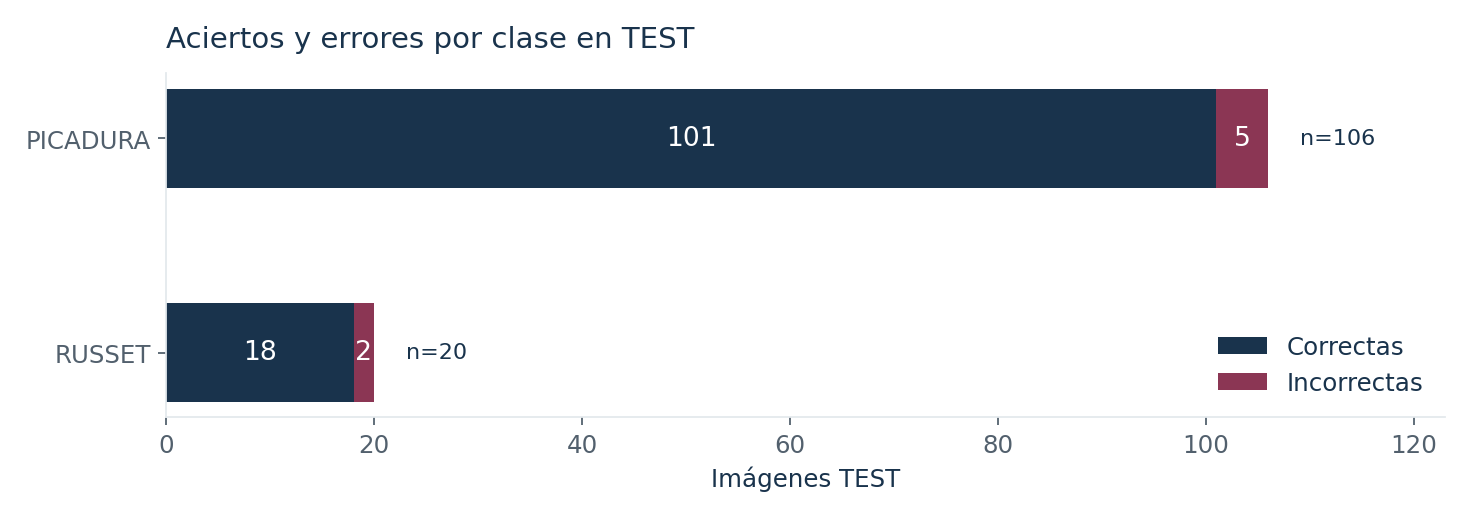

Figura 7. Aciertos y errores por clase en TEST según la matriz de confusión registrada.


## 12. Comparación descriptiva entre validation y TEST

| Métrica | Validation histórica | TEST | Diferencia (TEST − validation) |
|:--|--:|--:|--:|
| Accuracy | 0.8740 | 0.9444 | +0.0704 |
| Macro-F1 | 0.7876 | 0.9019 | +0.1143 |
| Recall RUSSET | 0.7143 | 0.9000 | +0.1857 |

Las métricas de TEST fueron mayores que las métricas históricas con las que se eligió el modelo. Se trata de una comparación descriptiva: los conjuntos no tienen exactamente las mismas imágenes ni el mismo número de RUSSET (21 en validation y 20 en TEST). No puede concluirse que el modelo haya mejorado después de validación, porque los pesos no cambiaron.

En la interpretación de esta tabla debe recordarse la reproducción de validation con una etiqueta discordante: los valores históricos son los utilizados para seleccionar el modelo; la ejecución posterior del checkpoint obtuvo 0.8661 de accuracy y 0.7781 de Macro-F1.


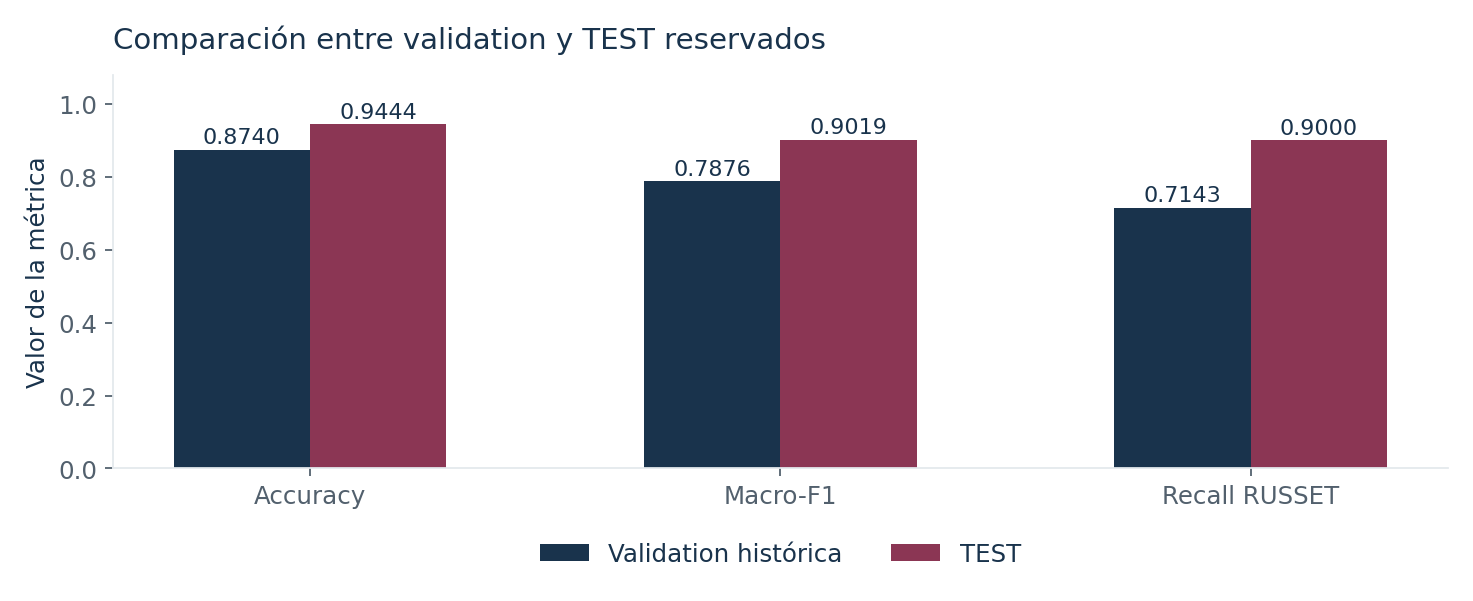

Figura 8. Comparación de los valores históricos de validation con los resultados de TEST del modelo seleccionado.


## 13. Incertidumbre y tamaño del conjunto de prueba

Los valores observados dependen de un conjunto limitado de imágenes. Utilizando intervalos de Wilson aproximados al 95 % para proporciones binomiales se obtiene:

| Medida | Proporción observada | Intervalo de Wilson aproximado 95 % |
|:--|--:|:--|
| Accuracy (119/126) | 0.9444 | 0.8898 a 0.9728 |
| Recall RUSSET (18/20) | 0.9000 | 0.6990 a 0.9721 |
| Recall PICADURA (101/106) | 0.9528 | 0.8943 a 0.9797 |

El intervalo de recall RUSSET es especialmente amplio porque solo hay 20 ejemplos. Estos intervalos suponen, de manera aproximada, observaciones independientes; si existen frutos correlacionados por lote o sesión, esa interpretación puede ser demasiado optimista. Los intervalos no equivalen a una garantía de desempeño para otras plantas o cámaras.

No se reporta un valor de significancia estadística de la diferencia validation–TEST, porque las dos muestras son diferentes y el estudio no fue diseñado como un contraste pareado de poblaciones equivalentes.


## 14. Análisis de los errores de TEST

Quedaron siete casos incorrectamente clasificados:

| Tipo de error | Cantidad | Consecuencia de clasificación |
|:--|--:|:--|
| PICADURA → RUSSET | 5 | Falsa identificación de RUSSET |
| RUSSET → PICADURA | 2 | RUSSET no detectada |

El aumento de recall RUSSET logrado en TEST es favorable. Sin embargo, la precisión de RUSSET es 0.7826, debido a que cinco imágenes PICADURA recibieron esa etiqueta. En una línea industrial, el impacto de cada confusión depende del destino comercial de la fruta y de los criterios de aceptación de calidad.

Como trabajo posterior se puede revisar visualmente cada uno de los siete TIFF y registrar observaciones sobre textura, iluminación, defectos coexistentes o consistencia de etiqueta. Esa revisión será descriptiva: no debe usarse para ajustar el umbral, seleccionar un nuevo checkpoint ni reentrenar sobre las mismas imágenes de TEST.


## 15. Alcance, limitaciones y controles de interpretación

1. La evidencia es de clasificación de PICADURA y RUSSET en las imágenes auditadas. No equivale a detección espacial del defecto.
2. El modelo se eligió después de varias comparaciones en una sola partición validation; esa selección puede generar optimismo en validation.
3. El conjunto TEST fue reservado y usado una sola vez, pero contiene 126 imágenes y solamente 20 RUSSET.
4. No hay evidencia suficiente para afirmar independencia por campaña, productor, lote, sesión o configuración de iluminación. La auditoría de duplicados exactos no reemplaza ese control.
5. Se documentó una diferencia numérica reproducible de una etiqueta en validation. Se aceptó una tolerancia posterior al hallazgo, por lo que la reproducibilidad exacta sigue pendiente.
6. Las puntuaciones softmax no se sometieron a una calibración independiente; no deben interpretarse automáticamente como confianza probabilística calibrada.
7. No se ha medido robustez en nuevas cámaras o entornos ni rendimiento en tiempo real de una línea de clasificación.
8. No debe utilizarse el TEST ya observado para optimizar el mismo modelo y presentar después el resultado como una prueba independiente.

Estas limitaciones no anulan los recuentos registrados; delimitan las inferencias que pueden extraerse de ellos.


## 16. Conclusiones del corte

1. El conjunto quedó auditado en 829 TIFF originales y 825 elegibles, con separación de train (572), validation (127) y TEST (126) y cuatro exclusiones lógicas documentadas.
2. Entre siete configuraciones evaluadas en validation, FT_D1_PHOTO presentó el mayor Macro-F1 registrado (0.7876) y se eligió antes de consultar TEST.
3. FT_D1_PHOTO detectó 15 de 21 RUSSET en validation, frente a 11 de 21 con FT_D1, manteniendo 111 aciertos globales en ambos casos.
4. La inferencia final sobre TEST registró 119 de 126 aciertos, accuracy 0.9444, Macro-F1 0.9019 y recall RUSSET 0.9000 (18 de 20 casos).
5. Los siete errores de TEST fueron cinco PICADURA predichas como RUSSET y dos RUSSET predichas como PICADURA.
6. La diferencia entre predicciones históricas y reproducción del checkpoint en una imagen de validation permanece documentada; la evaluación final se realizó con un modelo congelado y un criterio de compatibilidad numérica explícito.
7. Los resultados justifican continuar con la evaluación del método, pero no demuestran todavía robustez ante datos externos independientes ni viabilidad operativa en línea.


## 17. Próximas actividades recomendadas

| Orden | Actividad | Producto esperado |
|:--:|:--|:--|
| 1 | Cerrar y guardar `03_Evaluacion_Final_Test.ipynb` con la autorización desactivada | Evitar repetir TEST |
| 2 | Respaldar el checkpoint, la auditoría y los archivos `metricas_test.json`, `predicciones_test.csv` y `matriz_confusion_test.csv` | Trazabilidad de la corrida final |
| 3 | Leer el registro de las siete predicciones erróneas de TEST para una descripción cualitativa, sin cambiar el modelo | Análisis de errores final |
| 4 | Revisar la trazabilidad de fruto, lote y sesión para detectar dependencias que no capta SHA-256 | Limitación de independencia mejor caracterizada |
| 5 | Integrar métodos, resultados y limitaciones en el informe de investigación de maestría | Sección de resultados y discusión |
| 6 | En un estudio posterior, evaluar robustez con imágenes nuevas y un protocolo externo previamente fijado | Evaluación adicional verdaderamente independiente |

No se propone un nuevo entrenamiento con estas 126 imágenes: el conjunto TEST ya se utilizó y debe conservar su función de evidencia final de esta versión del modelo.


## 18. Archivos de evidencia y conservación

| Archivo o carpeta | Función |
|:--|:--|
| `1. fuentes/03_Corte_Avance_ResNet50_B0_V1_D1_D2.ipynb` | Primer corte experimental |
| `1. fuentes/04_Analisis_Errores_ResNet50.ipynb` | Fine-tuning y errores de validation |
| `1. fuentes/05_Analisis_Preprocesamiento.ipynb` | Ensayo de iluminación y preprocesamiento |
| `1. fuentes/06_Reporte_FT_D1_PHOTO.ipynb` | Selección del modelo y análisis emparejado |
| `1. fuentes/07_Reporte_Corte_Evaluacion_Final_ResNet50.ipynb` | Documento del corte actual |
| `6. entrenamiento/resnet50.ipynb` | Notebook de entrenamiento general |
| `6. entrenamiento/02_Experimento_Aumentos_Fotometricos.ipynb` | Experimento FT_D1_PHOTO |
| `6. entrenamiento/03_Evaluacion_Final_Test.ipynb` | Protocolo y única inferencia de TEST |
| `7. resultados/entrenamiento/FT_D1_PHOTO_s42_01/` | Configuración, checkpoint, historia y métricas de validation |
| `7. resultados/evaluacion_final/FT_D1_PHOTO_s42_01/` | Protocolo, auditoría, matriz, predicciones y métricas de TEST |

En la carpeta final se esperan `estado.json`, `protocolo_evaluacion.json`, `auditoria_test.json`, `manifiesto_test.csv`, `metricas_test.json`, `predicciones_test.csv`, `metricas_por_clase_test.csv`, `matriz_confusion_test.csv`, `matriz_confusion_test.png` y `comparacion_validation_test.csv`.

Conservar sin modificaciones los TIFF originales, los modelos anteriores y los pesos asociados a las corridas históricas.


## 19. Evidencia de la ejecución final

Las capturas siguientes corresponden a la salida de Jupyter compartida después de la verificación de integridad 829/829 y la inferencia de TEST 126/126. Se incluyen como registro de la corrida, junto con las figuras construidas a partir de la matriz de confusión.


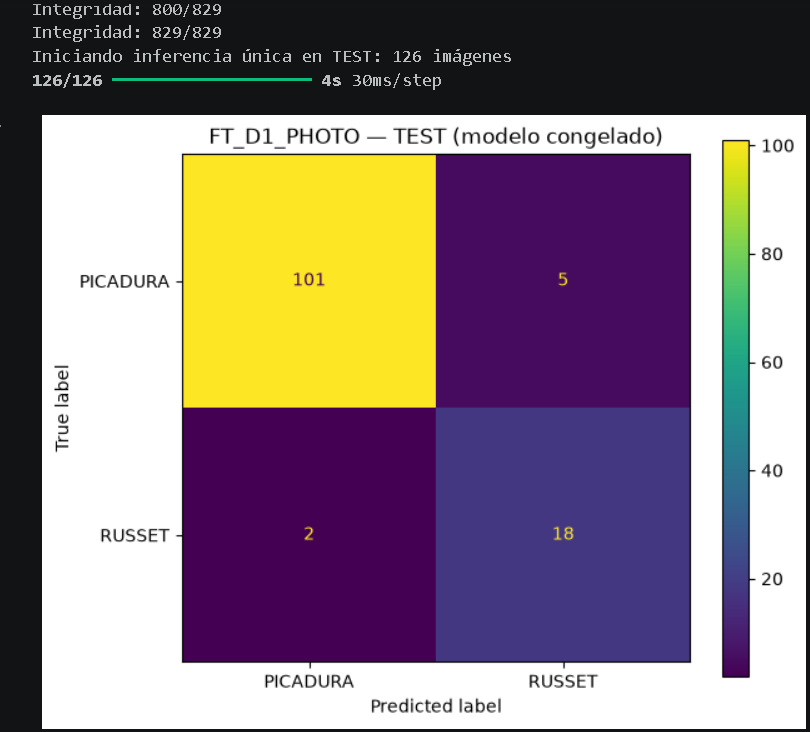

Figura 9. Salida registrada de la inferencia final y matriz de confusión original de TEST.


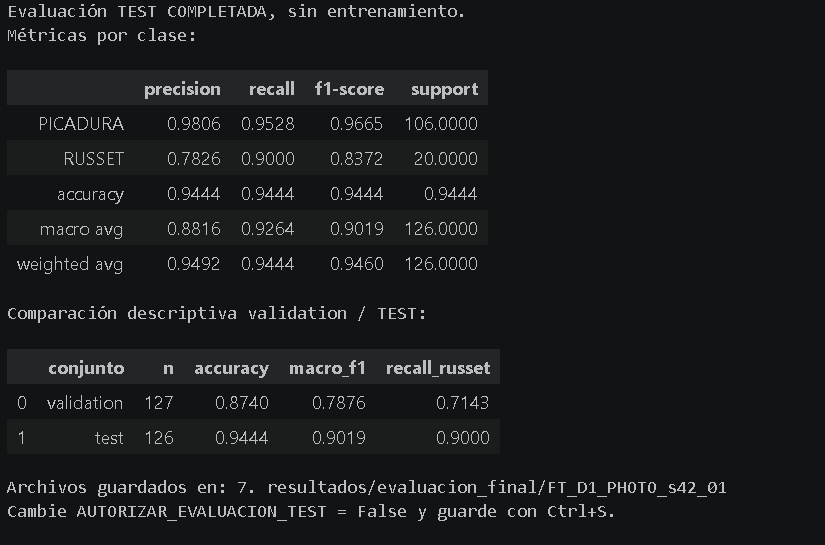

Figura 10. Reporte original de clasificación y comparación validation / TEST.


## 20. Comprobaciones opcionales de solo lectura

Estas celdas no son necesarias para leer el reporte. Solo se usan en el equipo que conserva la carpeta `PROYECTO_TI_2`. No importan TensorFlow, no cargan el modelo y no vuelven a realizar inferencia sobre TEST.

La primera comprobación muestra el contenido del archivo de métricas y contrasta su matriz con los recuentos documentados. Si faltan archivos, informa que no están disponibles; no crea carpetas ni modifica datos.


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display

raiz = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "README.md").is_file() and (p / "7. resultados").is_dir()),
    None
)

if raiz is None:
    print("No se encontro PROYECTO_TI_2. El informe es legible sin ejecutar esta celda.")
else:
    carpeta = raiz / "7. resultados" / "evaluacion_final" / "FT_D1_PHOTO_s42_01"
    metricas = carpeta / "metricas_test.json"
    matriz_csv = carpeta / "matriz_confusion_test.csv"
    estado = carpeta / "estado.json"
    if not all(p.is_file() for p in (metricas, matriz_csv, estado)):
        print("No estan disponibles todos los archivos de la evaluacion local.")
    else:
        registro = json.loads(metricas.read_text(encoding="utf-8"))
        status = json.loads(estado.read_text(encoding="utf-8"))
        matriz = pd.read_csv(matriz_csv, index_col=0).loc[
            ["PICADURA", "RUSSET"], ["PICADURA", "RUSSET"]
        ]
        esperada = np.array([[101, 5], [2, 18]])
        print("Estado de la evaluacion:", status.get("estado"))
        print("Modelo:", registro.get("modelo"))
        print("Imágenes:", registro.get("n_imagenes"))
        print("Matriz coincide con el corte:",
              bool(np.array_equal(matriz.to_numpy(), esperada)))
        display(pd.DataFrame([{
            "accuracy": registro.get("accuracy"),
            "macro_f1": registro.get("macro_f1"),
            "recall_russet": registro.get("recall_russet"),
            "aciertos": registro.get("aciertos"),
        }]).round(4))
        display(matriz)


### 20.1. Consulta opcional de las siete imágenes incorrectas

Esta consulta permite identificar las rutas y las puntuaciones registradas en el CSV de TEST. Su finalidad es documentar observaciones cualitativas, no cambiar el clasificador ni optimizar un umbral utilizando TEST.


In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display

raiz = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "README.md").is_file() and (p / "7. resultados").is_dir()),
    None
)
if raiz is None:
    print("No se encontro la carpeta del proyecto.")
else:
    ruta = (raiz / "7. resultados" / "evaluacion_final" /
            "FT_D1_PHOTO_s42_01" / "predicciones_test.csv")
    if not ruta.is_file():
        print("CSV de predicciones no encontrado:", ruta)
    else:
        pred = pd.read_csv(ruta)
        errores = pred.loc[
            pred["clase"] != pred["prediccion"],
            ["archivo", "clase", "prediccion",
             "probabilidad_PICADURA", "probabilidad_RUSSET"]
        ].copy()
        print("Total de errores registrados:", len(errores))
        display(errores.round(5))


---

Nota de procedencia: las tablas de B0 a FT_D1_PHOTO se basan en los cortes experimentales previos; las métricas, matriz de TEST, comprobaciones SHA-256 y comprobación de reproducción provienen de las salidas compartidas de `03_Evaluacion_Final_Test.ipynb`. Las figuras de comparación son reconstrucciones fieles de los recuentos observados, mientras que las capturas y curvas de entrenamiento son registros visuales de las ejecuciones. Este reporte no introduce resultados de experimentos no realizados.

Fin del corte 07.
